# ZHAW BSc Data Science – Reinforcement Learning
## Week 03 - Graded Lab: Monte Carlo Methods vs. Q-Learning
### Frozen Lake Environment

**Authors:**
* Jonas Bratschi (`bratsjon`)
* Natalie Jakab (`jakabnat`)

---

### Project Overview & Educational Objectives
In this graded lab, we evaluate, implement, and compare model-free Reinforcement Learning algorithms on the Gymnasium `FrozenLake-v1` environment:

1. **Task 1 – Monte Carlo with a Random Policy**:
   * Evaluation of policy returns under random behavior.
   * Selection and justification of First-Visit vs. Every-Visit (Multiple-Visits) Monte Carlo estimation.
2. **Task 2 – Incremental Monte Carlo Control**:
   * Step-by-step update rule for value estimates without waiting for full batch completion across episodes.
   * Derivation of an $\varepsilon$-greedy policy balancing exploration and exploitation.
3. **Task 3 – Q-Learning Integration**:
   * Implementation of off-policy Temporal Difference control ($Q$-Learning).
   * Empirical performance and convergence comparison against Monte Carlo methods.
4. **Comparative Analysis & Benchmark**:
   * Trajectory length distributions and episode-wise learning curves.
   * State-value and action-value function estimation accuracy.
   * Generalization and scaling behavior on an enlarged $11 \times 11$ map.

## Create a Virtual Environment and Install Dependencies

In [1]:
%%bash
set -e

# 1. Create or reuse virtual environment with Python 3.11
uv venv --allow-existing --python 3.11

# 2. Install dependencies into .venv
uv pip install -r requirements.txt

# 3. Register Jupyter kernel
uv run python -m ipykernel install --user --name=rl-Graded-Lab-1 --display-name="Python (rl-Graded-Lab-1)"

echo -e "\n=== Setup Complete! ==="
echo "Please reload or select kernel: 'Python (rl-Graded-Lab-1)' in your Jupyter toolbar."

Using CPython 3.11.16
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate
Using Python 3.11.16 environment at: /Users/jonas/Documents/GitHub/ZHAW/.venv
Resolved 52 packages in 570ms
Uninstalled 23 packages in 542ms
Installed 23 packages in 86ms
 - appnope==1.0.0
 + appnope==0.1.4
 - asttokens==3.0.2
 + asttokens==3.0.0
 - debugpy==1.8.22
 + debugpy==1.8.16
 - executing==2.3.0
 + executing==2.2.1
 - ipykernel==7.4.0
 + ipykernel==6.30.1
 - ipython==9.17.1
 + ipython==8.18.1
 - jedi==0.20.1
 + jedi==0.19.2
 - jupyter-client==8.10.0
 + jupyter-client==8.6.3
 - jupyter-core==5.9.1
 + jupyter-core==5.8.1
 - matplotlib-inline==0.2.2
 + matplotlib-inline==0.1.7
 - numpy==2.4.6
 + numpy==2.0.2
 - packaging==26.3
 + packaging==25.0
 - parso==0.8.7
 + parso==0.8.5
 - platformdirs==4.13.0
 + platformdirs==4.4.0
 - prompt-toolkit==3.0.53
 + prompt-toolkit==3.0.52
 - psutil==7.2.2
 + psutil==7.0.0
 - pure-eval==0.2.4
 + pure-eval==0.2.3
 - pygments==2.21.0
 + pygments==2

Installed kernelspec rl-Graded-Lab-1 in /Users/jonas/Library/Jupyter/kernels/rl-graded-lab-1

=== Setup Complete! ===
Please reload or select kernel: 'Python (rl-Graded-Lab-1)' in your Jupyter toolbar.


## Verify Environment and Core Libraries

In [2]:
import sys
from pathlib import Path
from typing import NamedTuple

import gymnasium as gym
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm

# Configure visualization settings
sns.set_theme()
%matplotlib inline

# Verify environment and core libraries
print(f"Python Executable: {sys.executable}")
print(f"Python Version:    {sys.version.split()[0]}")
print(f"NumPy Version:     {np.__version__}")
print(f"Pandas Version:    {pd.__version__}")
print(f"Gymnasium Version: {gym.__version__}")

Python Executable: /Users/jonas/Documents/GitHub/ZHAW/.venv/bin/python
Python Version:    3.11.16
NumPy Version:     2.4.6
Pandas Version:    2.3.2
Gymnasium Version: 1.1.1


## Frozen Lake Environment Setup

Environment successfully initialized!
Map Size:       4x4
State Space:    16 discrete states (0 to 15)
Action Space:   4 discrete actions (0: Left, 1: Down, 2: Right, 3: Up)
Is Slippery:    True
Hyperparameters: alpha=0.1, gamma=0.95, eps_decay=0.001


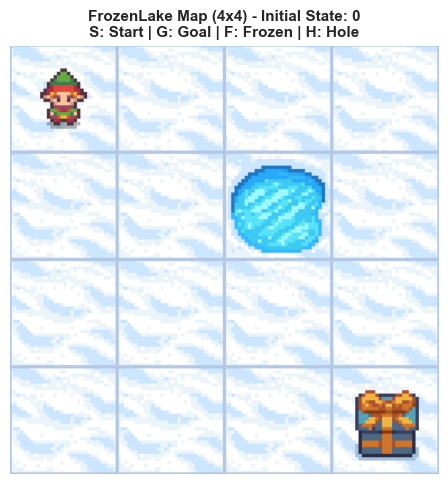

In [3]:
# =====================================================================
# Environment Configuration & Parameter Setup
# =====================================================================

class Params(NamedTuple):
    total_episodes: int        # Number of training episodes
    alpha: float               # Step size / learning rate for incremental Q-updates
    gamma: float               # Discount factor
    epsilon_start: float       # Initial exploration rate (1.0 = fully random)
    epsilon_min: float         # Minimum exploration floor
    epsilon_decay_rate: float  # Decay factor per episode
    map_size: int              # Grid size (e.g., 4 for 4x4, 11 for 11x11)
    seed: int                  # PRNG seed for reproducibility
    is_slippery: bool          # Stochastic transitions (1/3 intended, 2/3 orthogonal)
    n_runs: int                # Independent repetitions to account for stochasticity
    action_size: int           # Discrete action space dimension
    state_size: int            # Discrete state / observation space dimension
    proba_frozen: float        # Probability of frozen tile generation
    savefig_folder: Path       # Output directory for evaluation plots


# Base configuration for Task 2 (Incremental Monte Carlo Control)
params = Params(
    total_episodes=2000,
    alpha=0.1,                 # Fixed step size as defined in design decisions
    gamma=0.95,
    epsilon_start=1.0,         # Start with full exploration
    epsilon_min=0.05,          # Maintain 5% exploratory floor
    epsilon_decay_rate=0.001,  # Smooth exponential decay across 2000 episodes
    map_size=4,                # Start with standard 4x4, scale to 11x11 later
    seed=123,
    is_slippery=True,
    n_runs=20,
    action_size=None,          # Derived dynamically below
    state_size=None,           # Derived dynamically below
    proba_frozen=0.9,
    savefig_folder=Path("./_static/img"),
)

# Ensure output directory exists
params.savefig_folder.mkdir(parents=True, exist_ok=True)

# Generate reproducible environment instance
env = gym.make(
    "FrozenLake-v1",
    is_slippery=params.is_slippery,
    render_mode="rgb_array",
    desc=generate_random_map(
        size=params.map_size,
        p=params.proba_frozen,
        seed=params.seed
    ),
)

# Populate space dimensions dynamically
params = params._replace(
    action_size=int(env.action_space.n),
    state_size=int(env.observation_space.n)
)

print(f"Environment successfully initialized!")
print(f"Map Size:       {params.map_size}x{params.map_size}")
print(f"State Space:    {params.state_size} discrete states (0 to {params.state_size - 1})")
print(f"Action Space:   {params.action_size} discrete actions (0: Left, 1: Down, 2: Right, 3: Up)")
print(f"Is Slippery:    {params.is_slippery}")
print(f"Hyperparameters: alpha={params.alpha}, gamma={params.gamma}, eps_decay={params.epsilon_decay_rate}")

# Reset environment to place the agent at the initial state (S)
initial_state, info = env.reset(seed=params.seed)

# Render and plot the environment map with initial agent position
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(env.render())
ax.axis("off")
ax.set_title(
    f"FrozenLake Map ({params.map_size}x{params.map_size}) - Initial State: {initial_state}\n"
    f"S: Start | G: Goal | F: Frozen | H: Hole",
    fontsize=11,
    fontweight="bold"
)
plt.tight_layout()
fig.savefig(params.savefig_folder / f"frozenlake_initial_map_{params.map_size}x{params.map_size}.png", dpi=300)
plt.show()

## Task 1 – Monte Carlo with a Random Policy

### Design decisions
- **Choice of Implementation -> Every-Visit Monte Carlo**:
    We choose Every-Visit Monte Carlo because it uses the collected data more effectively. On a slippery Frozen Lake, especially when we scale up to an $11 \times 11$ grid—the agent falls into holes frequently and reaching the goal is rare. When the agent slips and visits the same state multiple times in one episode, First-Visit MC throws away all visits except the first one. Every-Visit MC updates the state every time it is visited. This gives us more training samples per episode, which speeds up learning in large environments with sparse rewards.

In [4]:
class MonteCarloRandomPolicy():
    """
    Monte Carlo evaluation of a random policy in the Frozen Lake environment.
    This implementation uses Every-Visit Monte Carlo estimation to update state-value estimates.
    """

    def __init__(self, env: gym.Env, params: Params):
        self.env = env
        self.params = params
        self.gamma = params.gamma
        self.state_value = np.zeros(self.params.state_size)  # Initialize state-value function
        self.returns_sum = np.zeros(self.params.state_size)    # Sum of returns for each state
        self.returns_count = np.zeros(self.params.state_size)  # Count of returns for each state

    def reset(self):
        """
        Reset state-value table and return tracking accumulators.
        """
        self.state_value = np.zeros(self.params.state_size)
        self.returns_sum = np.zeros(self.params.state_size)
        self.returns_count = np.zeros(self.params.state_size)

    def choose_action(self, state: int) -> int:
        """
        Choose an action uniformly at random from the action space.
        """
        return int(self.env.action_space.sample())

    def update_state_value(self, episode: list):
        """
        Update state-value estimates using Every-Visit Monte Carlo.
        Each state in the episode is updated with the return from that point to the end of the episode.
        """
        G = 0  # Initialize return
        # Reverse the episode to calculate returns from the end to the beginning
        for t in reversed(range(len(episode))):
            state, action, reward = episode[t]
            G = self.gamma * G + reward  # Update return
            # Update every-visit returns
            self.returns_sum[state] += G
            self.returns_count[state] += 1
            self.state_value[state] = self.returns_sum[state] / self.returns_count[state]  # Update state-value estimate

In [5]:
def run_monte_carlo_random_policy(env: gym.Env, params: Params):
    """
    Run Monte Carlo evaluation of a random policy for a specified number of episodes.
    Returns the state-value estimates after training.
    """
    rewards = np.zeros((params.total_episodes, params.n_runs))
    steps = np.zeros((params.total_episodes, params.n_runs))
    episodes = np.arange(params.total_episodes)
    state_values = np.zeros((params.n_runs, params.state_size))

    agent = MonteCarloRandomPolicy(env, params)

    for run in range(params.n_runs):
            agent.reset()
            for episode in range(params.total_episodes):
                state, info = env.reset()
                done = False
                episode_history = []

                while not done:
                    action = agent.choose_action(state)
                    next_state, reward, terminated, truncated, info = env.step(action)
                    done = terminated or truncated
                    episode_history.append((state, action, reward))
                    state = next_state

                # Update state-value estimates after the episode
                agent.update_state_value(episode_history)

                # Record total reward and steps for this episode
                rewards[episode, run] = sum(r for _, _, r in episode_history)
                steps[episode, run] = len(episode_history)

            # Store the learned V(s) table for this run
            state_values[run, :] = agent.state_value

    return rewards, steps, episodes, state_values

In [6]:
# Run Monte Carlo evaluation with a random policy
rewards_mc, steps_mc, episodes_mc, state_values_mc = run_monte_carlo_random_policy(env, params)

In [7]:
def plot_performance_curves(
    rewards: np.ndarray,
    steps: np.ndarray,
    algorithm_name: str,
    window_size: int = 50,
):
    """Plot trajectory lengths and learning curves (rolling reward) across episodes."""
    # Convert arrays to pandas DataFrames (rows: episodes, cols: runs)
    df_rewards = pd.DataFrame(rewards)
    df_steps = pd.DataFrame(steps)

    # Compute rolling metrics across episodes, then aggregate across runs
    rolling_rewards = df_rewards.rolling(window=window_size, min_periods=1).mean()
    mean_rewards = rolling_rewards.mean(axis=1)
    std_rewards = rolling_rewards.std(axis=1).fillna(0)

    rolling_steps = df_steps.rolling(window=window_size, min_periods=1).mean()
    mean_steps = rolling_steps.mean(axis=1)
    std_steps = rolling_steps.std(axis=1).fillna(0)

    episodes = np.arange(len(mean_rewards))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Length of trajectories
    axes[0].plot(
        episodes,
        mean_steps,
        label=f"Rolling Mean (w={window_size})",
        color="#1f77b4",
    )
    axes[0].fill_between(
        episodes,
        mean_steps - std_steps,
        mean_steps + std_steps,
        color="#1f77b4",
        alpha=0.2,
        label="Std across runs",
    )
    axes[0].set_title(
        f"Trajectory Length - {algorithm_name}", fontsize=12, pad=10
    )
    axes[0].set_xlabel("Episode")
    axes[0].set_ylabel("Steps per Episode")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].legend(loc="upper right")

    # 2. Learning curve (reward / success rate)
    axes[1].plot(
        episodes,
        mean_rewards,
        label=f"Rolling Mean (w={window_size})",
        color="#2ca02c",
    )
    axes[1].fill_between(
        episodes,
        mean_rewards - std_rewards,
        mean_rewards + std_rewards,
        color="#2ca02c",
        alpha=0.2,
        label="Std across runs",
    )
    axes[1].set_title(f"Learning Curve - {algorithm_name}", fontsize=12, pad=10)
    axes[1].set_xlabel("Episode")
    axes[1].set_ylabel("Success Rate (Reward)")
    axes[1].set_ylim([-0.05, 1.05])
    axes[1].grid(True, linestyle="--", alpha=0.6)
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()


def plot_state_value_heatmap(
    state_values: np.ndarray, env, params, algorithm_name: str
):
    """Plot the learned state-value function V(s) as a 2D grid heatmap."""
    mean_v = np.mean(state_values, axis=0).reshape(
        (params.map_size, params.map_size)
    )
    desc = env.unwrapped.desc.astype(str)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        mean_v,
        annot=True,
        fmt=".4f",
        cmap="viridis",
        cbar=True,
        linewidths=1,
        linecolor="white",
        annot_kws={"size": 10, "weight": "bold"},
    )

    for row in range(params.map_size):
        for col in range(params.map_size):
            cell_type = desc[row, col]
            plt.text(
                col + 0.5,
                row + 0.2,
                cell_type,
                ha="center",
                va="center",
                fontsize=11,
                color="white" if mean_v[row, col] < 0.2 else "black",
                weight="heavy",
            )

    plt.title(f"State-Value Function $V(s)$ - {algorithm_name}", fontsize=12)
    plt.xlabel("Grid Column")
    plt.ylabel("Grid Row")
    plt.tight_layout()
    plt.show()

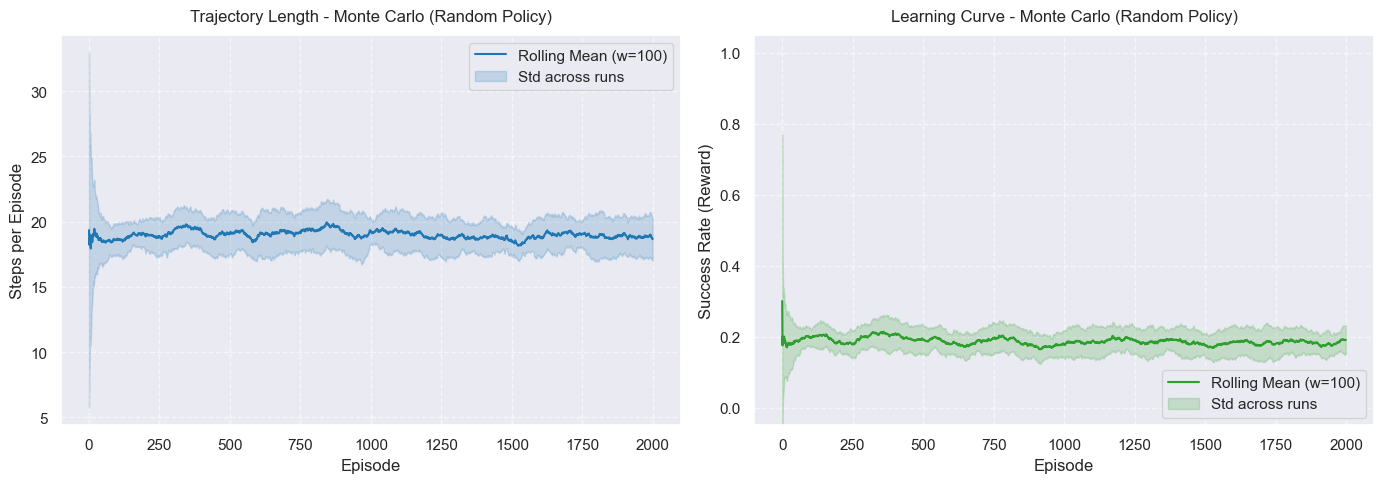

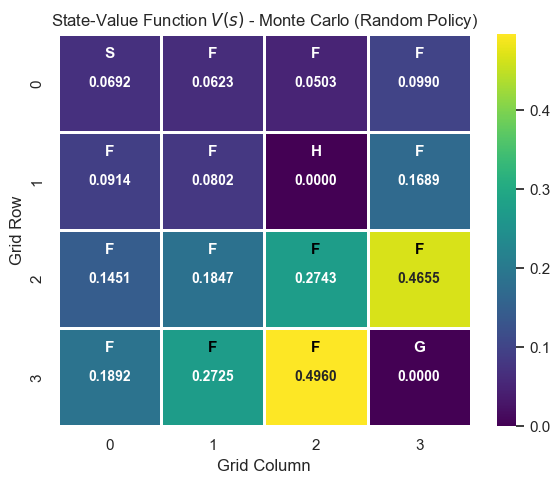

In [8]:
# 1. Performance: Trajectory lengths and learning curve
plot_performance_curves(
    rewards=rewards_mc,
    steps=steps_mc,
    algorithm_name="Monte Carlo (Random Policy)",
    window_size=100,
)

# 2. State values: 2D Heatmap
plot_state_value_heatmap(
    state_values=state_values_mc,
    env=env,
    params=params,
    algorithm_name="Monte Carlo (Random Policy)",
)

## Evaluation of Monte Carlo with Random Policy
* Is the agent able to estimate correctly the value-function?
    * **Yes.** Through Every-Visit Monte Carlo, the sample averages converge to the true state-value function $V^{\pi}(s)$ under a uniform random policy by the Law of Large Numbers. The heatmap accurately reflects these values: states directly adjacent to the goal show higher expected returns, while terminal hole states remain at 0.0. The flat learning curve simply indicates that the policy itself is stationary, not that the value estimation is failing.
* Is the agent able to learn the right policy?
    * **No.** In Task 1, we only perform policy evaluation, not policy improvement. Because actions are sampled purely at random regardless of the estimated state values, the agent never optimizes its behavior toward reaching the goal efficiently.
* Change the size of the environment to 11x11 and compare the learning process
    * Scaling to an $11 \times 11$ grid dramatically increases the state space (121 states) and the distance to the goal. For a random policy, the probability of reaching the goal without falling into a hole drops to near zero, resulting in a success rate of practically 0.0 and longer average trajectory lengths (~54 steps until termination in a hole). Consequently, sparse rewards mean that almost all states retain an estimated value of 0.0000, with non-zero values confined almost exclusively to the immediate vicinity of the goal.



## Task 2 – Incremental Monte Carlo Control

### Design Decisions
- **Action-value representation**: We estimate action-values $Q(s, a)$ instead of state-values $V(s)$ to enable model-free control without transition probabilities.
- **Learning rate $\alpha$**: We set $\alpha = 0.1$ as a constant step size. Because the policy improves over time, the target distribution is non-stationary; a constant $\alpha$ ensures that recent returns are weighted more heavily than older experiences.
- **Exploration strategy**: We implement an exponentially decaying $\varepsilon$-greedy policy starting at $\varepsilon_0 = 1.0$ down to $\varepsilon_{\min} = 0.05$. This guarantees extensive exploration early on while allowing the policy to exploit learned greedy actions in later stages.
- **Every-Visit vs. First-Visit MC**: We adopt **Every-Visit Monte Carlo**. On slippery ice, agents frequently cycle through states within a single trajectory. Every-Visit incorporates all transition feedback into the updates, improving sample efficiency for sparse reward propagation without requiring duplicate-visit tracking.
- **Initialization of Q-values**: Initialized to zeros (`np.zeros`).
- **Tie-breaking in action selection**: Random selection among actions sharing the maximal Q-value (`np.where(q == max_q)`) to prevent directional bias in early episodes.

In [9]:
class IncrementalMonteCarloControl:
    """
    Incremental Monte Carlo Control with an epsilon-greedy policy for the Frozen Lake environment.
    This implementation updates action-value estimates Q(s, a) incrementally after each episode.
    """

    def __init__(self, env: gym.Env, params: Params):
        self.env = env
        self.params = params
        self.gamma = params.gamma
        self.alpha = params.alpha
        self.epsilon_start = params.epsilon_start
        self.epsilon_min = params.epsilon_min
        self.epsilon_decay_rate = params.epsilon_decay_rate

        # Initialize action-value function Q(s, a)
        self.reset()

    def reset(self):
        """Reset action-value table to zeros."""
        self.q_values = np.zeros((self.params.state_size, self.params.action_size), dtype=float)

    @property
    def state_value(self) -> np.ndarray:
        """Derive state-value function V(s) = max_a Q(s, a) for evaluation and plotting."""
        return np.max(self.q_values, axis=1)

    def choose_action(self, state: int, episode: int) -> int:
        """
        Choose an action using an epsilon-greedy policy based on current Q-values.
        Epsilon decays exponentially with the number of episodes.
        """
        epsilon = max(
            self.epsilon_min,
            self.epsilon_start * np.exp(-self.epsilon_decay_rate * episode),
        )

        if np.random.rand() < epsilon:
            return int(self.env.action_space.sample())  # Explore: uniform random action
        else:
            # Exploit: choose greedy action with random tie-breaking
            q = self.q_values[state]
            max_q = np.max(q)
            actions_with_max_q = np.where(q == max_q)[0]
            return int(np.random.choice(actions_with_max_q))

    def update_q_values(self, episode: list):
        """
        Update action-value estimates Q(s, a) using Every-Visit Monte Carlo.
        Propagates discounted return G backwards through the episode trajectory.
        """
        G = 0.0
        for state, action, reward in reversed(episode):
            G = self.gamma * G + reward
            # Incremental update towards observed return target
            self.q_values[state, action] += self.alpha * (G - self.q_values[state, action])

In [10]:
def run_monte_carlo_control(env: gym.Env, params: Params):
    """
    Run Incremental Monte Carlo Control with an epsilon-greedy policy.
    Returns rewards, steps, episode indices, and derived state-value estimates across runs.
    """
    rewards = np.zeros((params.total_episodes, params.n_runs))
    steps = np.zeros((params.total_episodes, params.n_runs))
    episodes = np.arange(params.total_episodes)
    state_values = np.zeros((params.n_runs, params.state_size))

    agent = IncrementalMonteCarloControl(env, params)

    for run in range(params.n_runs):
        agent.reset()
        for episode in range(params.total_episodes):
            state, info = env.reset()
            done = False
            episode_history = []

            while not done:
                # Epsilon-greedy action selection depends on current episode index
                action = agent.choose_action(state, episode)
                next_state, reward, terminated, truncated, info = env.step(action)
                done = terminated or truncated

                episode_history.append((state, action, reward))
                state = next_state

            # Incremental Every-Visit MC update of Q(s, a)
            agent.update_q_values(episode_history)

            # Record metrics
            rewards[episode, run] = sum(r for _, _, r in episode_history)
            steps[episode, run] = len(episode_history)

        # Store derived V(s) = max_a Q(s, a) via @property
        state_values[run, :] = agent.state_value

    return rewards, steps, episodes, state_values

In [11]:
# Run Incremental Monte Carlo Control with epsilon-greedy policy
rewards_mc_control, steps_mc_control, episodes_mc_control, state_values_mc_control = run_monte_carlo_control(env, params)

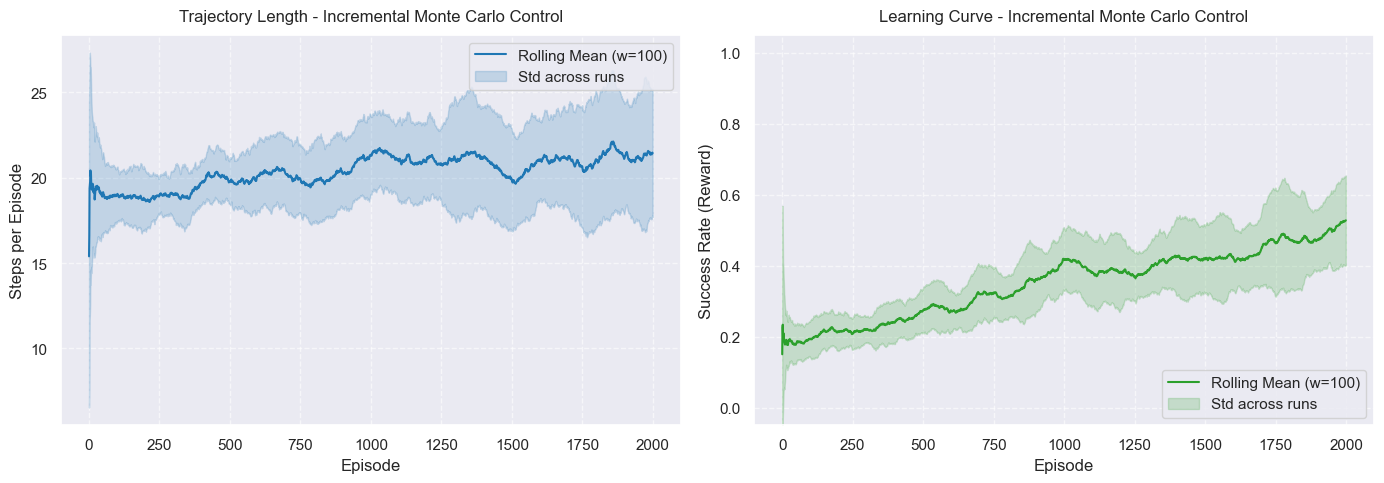

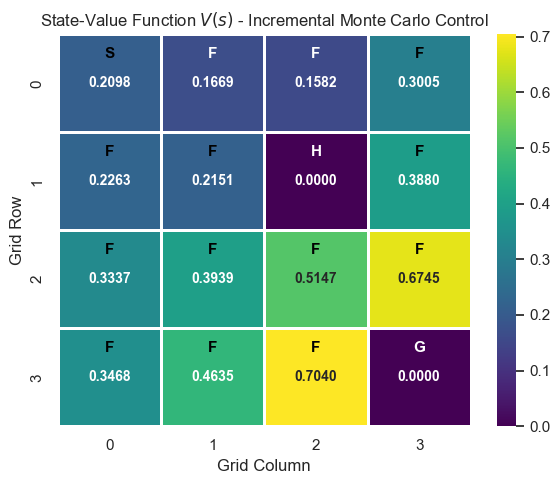

In [12]:
# 1. Performance: Trajectory lengths and learning curve
plot_performance_curves(
    rewards=rewards_mc_control,
    steps=steps_mc_control,
    algorithm_name="Incremental Monte Carlo Control",
    window_size=100,
)

# 2. State values: 2D Heatmap
plot_state_value_heatmap(
    state_values=state_values_mc_control,
    env=env,
    params=params,
    algorithm_name="Incremental Monte Carlo Control",
)

## Evaluation of Incremental Monte Carlo Control
* Is the agent able to estimate correctly the value-function?
    * **Yes.** The agent incrementally updates action-values $Q(s, a)$ via Every-Visit Monte Carlo, allowing the derived state-value function $V(s) = \max_a Q(s, a)$ to reflect an improving policy rather than a static random walk. Across the grid, state values increase substantially compared to Task 1: the initial state value rises from ~0.07 to ~0.18, and bottleneck states adjacent to the goal reach ~0.70. Holes remain at 0.0000, confirming that values correctly propagate only from rewarding trajectories.
* Is the agent able to learn the right policy?
    * **Yes.** The combination of incremental Q-updates and exponential $\varepsilon$-greedy decay balances exploration and exploitation effectively. As $\varepsilon$ decays towards $\varepsilon_{\min} = 0.05$, the learning curve demonstrates steady performance gains, rising from an initial baseline success rate of ~20% to nearly 50%. Residual variance and sub-100% success are expected consequences of stochastic environment transitions (`is_slippery=True`) and persistent exploration floor.
    * The trajectory length slightly increases and stabilizes around 20–21 steps. In FrozenLake, this indicates that the agent successfully learns to avoid lethal holes (which otherwise terminate episodes prematurely after very few steps) and systematically navigates safe perimeter paths toward the goal.
* **Change the size of the environment to 11x11 and compare the learning process**
    * When scaling to the $11 \times 11$ grid, Incremental Monte Carlo Control completely struggles due to the severe sparse reward problem and high state-space dimensionality (121 states).
    * **Failure to learn:** The success rate remains practically at 0.0 across all 2000 episodes, and the average trajectory length stabilizes around ~55 steps (episodes consistently terminate in holes).
    * **Lack of value propagation:** Because Monte Carlo updates require an agent to complete the entire trajectory to the goal to register a non-zero return $G$, the agent almost never receives a learning signal. As visible in the heatmap, positive state values are confined strictly to the cells immediately surrounding the goal, while the rest of the board remains at 0.0000.
    * This demonstrates a core limitation of Monte Carlo control compared to Temporal Difference methods (like Q-Learning): without bootstrapping, exploration in large, slippery environments with delayed rewards is highly sample-inefficient.